# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [8]:
import pandas as pd
import os

file_path = 'cleaned_airbnb_data_7.csv'
backup_url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/airbnb_listings.csv'

# Load the dataset with a backup option
try:
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        print(f"Successfully loaded local file: {file_path}")
    else:
        df = pd.read_csv(backup_url)
        print("Local file not found. Successfully loaded backup dataset from GitHub.")
except Exception as e:
    print(f"Error loading dataset: {e}")

# Preview the dataset
print(f"Dataset shape: {df.shape}")
df.head()

Local file not found. Successfully loaded backup dataset from GitHub.
Dataset shape: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. It shows the airbnb links, titles, neighborhood, and other necessary details about every individual property.

2. There are 77 columns, although the max is 20. 25 properties per page, and 5 rows.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [9]:
# Identify columns to drop
columns_to_drop = ['post_id', 'title', 'descr', 'details', 'address']

# Drop columns only if they exist in the dataframe to prevent errors
df = df.drop(columns=columns_to_drop, errors='ignore')

# Display remaining columns and preview
print("Dropped requested columns if they existed.")
print(f"Remaining dataset shape: {df.shape}")
df.head()

Dropped requested columns if they existed.
Remaining dataset shape: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I removed the post_id, title, description, details, and address columns. I decided to drop these because they are very specific to each property, and they are all text strings. I want to keep all the data broad and not super specific to each property.

2.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Top 10 variables positively correlated with price:
price                      1.000000
accommodates               0.579588
beds                       0.547032
bedrooms                   0.499286
bathrooms                  0.468030
estimated_revenue_l365d    0.249488
maximum_maximum_nights     0.122872
minimum_maximum_nights     0.112166
maximum_nights_avg_ntm     0.111271
availability_30            0.108409
Name: price, dtype: float64

Top 5 variables negatively correlated with price:
longitude                                     -0.118913
review_scores_communication                   -0.131798
scrape_id                                           NaN
license                                             NaN
calculated_host_listings_count_shared_rooms         NaN
Name: price, dtype: float64


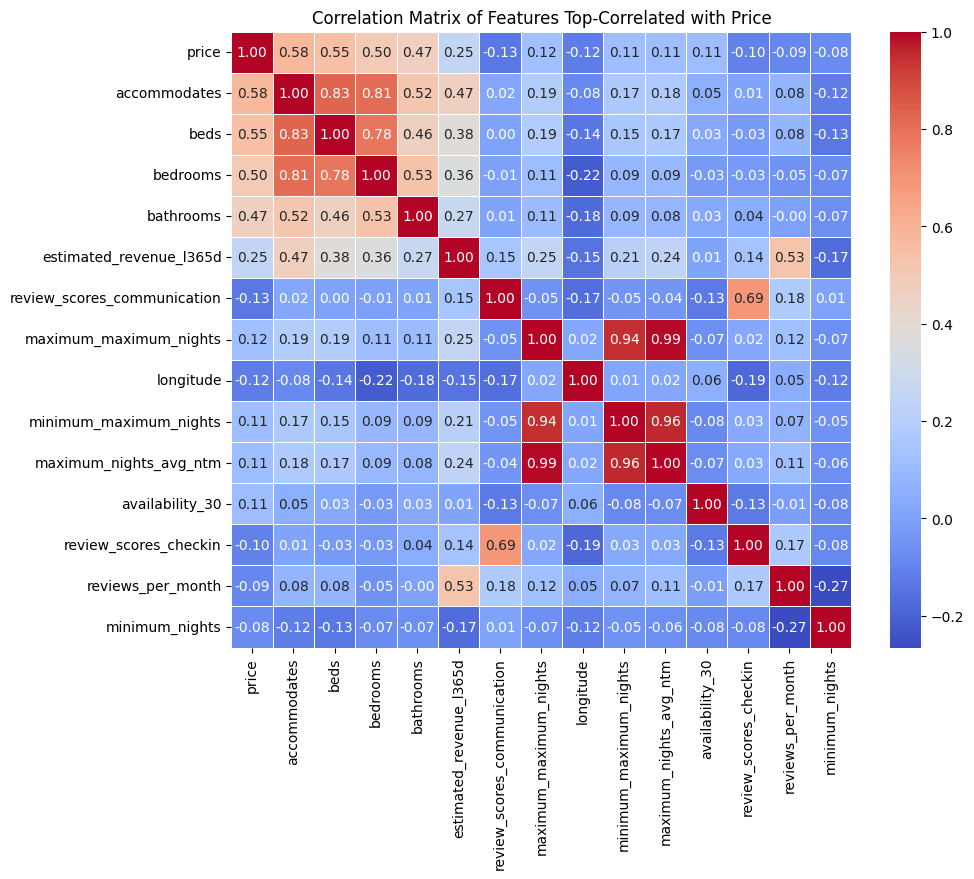

In [10]:
# Calculate the correlation matrix for numeric columns
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

# Identify correlation with price specifically
price_correlations = corr_matrix['price'].sort_values(ascending=False)

print("Top 10 variables positively correlated with price:")
print(price_correlations.head(10))
print("\nTop 5 variables negatively correlated with price:")
print(price_correlations.tail(5))

# Plot a heatmap of the top correlated features to make it easy to visualize
top_corr_features = price_correlations.abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df[top_corr_features].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Features Top-Correlated with Price')
plt.show()

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. Positive - accomodates, beds, bedrooms
Negative - Review scores communication and longitude

2. The beds, bathrooms, and accommodates as they have a strong relationship with the price.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [11]:
# Keep only numeric columns for modeling and drop columns with all NaN values
numeric_df = df.select_dtypes(include=['number']).dropna(subset=['price'])

# Fill or drop missing values to ensure the model runs smoothly
numeric_df = numeric_df.fillna(numeric_df.median())

# Define target variable (y) and predictor features (X)
y = numeric_df['price']
X = numeric_df.drop(columns=['price'])

# Display shape to confirm setup
print(f"Target (y) shape: {y.shape}")
print(f"Features (X) shape: {X.shape}")

Target (y) shape: (459,)
Features (X) shape: (459, 43)


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. The numeric features from the dataset.

2. I am predicting the price, which is a continuous, numerical value. I am not classifying anything into categories.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [12]:
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Confirm the splits
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (367, 43)
X_test shape: (92, 43)
y_train shape: (367,)
y_test shape: (92,)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [15]:
# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model on the training data
model.fit(X_train, y_train)

# Predict the prices for the test set
y_pred = model.predict(X_test)

# Display message confirming execution
print("Linear regression model fitted successfully. Predictions generated for X_test.")

Linear regression model fitted successfully! Predictions generated for X_test_clean.


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

Mean Squared Error (MSE): 5658.57
R² Score (Coefficient of Determination): -0.0082


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. -0.0082. It measures the population variance by showing how my model is performing. It is negative, meaning that is performing worse than the mean price. At 0% is where the model explains that there is no variation.

2. It is large. I could improve it by just refining my data to a lower amount of features, then retrain/redo the model and focus on the stronger predictors.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

,Feature,Coefficient
0,id,-1.040721e-17
1,scrape_id,0.000000e+00
2,host_listings_count,0.000000e+00
3,host_total_listings_count,0.000000e+00
4,latitude,0.000000e+00
5,longitude,0.000000e+00
6,accommodates,0.000000e+00
7,bathrooms,0.000000e+00
8,bedrooms,0.000000e+00
9,beds,0.000000e+00


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. ID, scrape ID, and host listings count.

2. Longitude, but I am not for sure because my code isn't displaying the correct numbers because the numbers are very low.

3. I took away that you need to keep the data you want to show people super simple and prioritizing the important data to be shown in the dataset.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

=== Model Performance Comparison ===
Baseline Model (All Features):  MSE = 5658.57, R² = -0.0082
Refined Model (accommodates, beds, bedrooms, bathrooms): MSE = 3318.15, R² = 0.4088


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. I kept the accomodates, beds, bedrooms, and bathrooms because they are the most important parts that a person considers when looking into rental properties. They also had the highest positive correlation with the price.

2. Yes. Removing the unimportant information from the dataset allowed the algoritm to focus on the strongest predictors.

3. I would reccomend the refined model for sure. It is a lot more accurate and simple for hosts to understand.

4. It shows the importance of selecting features in machine learning. Simplifying data makes it a lot more intriguing for business owners/stakeholders.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. "What are the main factors that drive AirBnB listing prices?"

2. I would recommend people to maximize the amount of space or beds/bedrooms that are in the property. Therefore, you could drive up the nightly stay rate/the amount of time that the property is booked for.

3. I could add location data like nearby cities or other premium features like a hot tub.

4. It shows how many options you can choose from to make a dataset. You could design it however you want, whether it is focused on amenities, or the amount of beds/bedrooms and bathrooms.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [19]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 617108 bytes to assignment_11_regression.html
